## Imports and Config

In [1]:
%load_ext autoreload
%autoreload 2

Custom imports from the `config/settings.py` file.

In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from haystack import Pipeline, Document
from hayhooks import BasePipelineWrapper
from haystack_integrations.components.retrievers.qdrant import QdrantEmbeddingRetriever

In [4]:
from sem_rag.config.settings import Qdrant, LAMEDataset
from sem_rag.storage.qdrant import get_document_store
from sem_rag.retrieval.components import QueryMetadataExtractor, QueryEmbedder, MMRReranker
from sem_rag.retrieval.schemas.lame import METADATA_SCHEMA, EXTRACTION_SYSTEM_PROMPT
from sem_rag.image.encoding import encode_image

In [5]:
MMR_CANDIDATES = 50

In [6]:
TEXT_QUERIES = [
    "Find images of the carbon nano tubes with different diameters.",
    "Find the images of the nanoparticle clusters that are evenly distributed on the surface.",
    "Find the images with patterning with parallel lines geometry.",
    "Find the thin film SEM images."
]

TEXT_META_QUERIES = [
    "Find images of the carbon nano tubes with different diameters having a magnification greater than 50kx.",
    "Find the images of the nanoparticle clusters that are evenly distributed on the surface with same magnification and different acelerating voltages.",
    "Find the SEM images of the graphene nanoparticles with STEM detector."
]

In [7]:
IMAGE_QUERIES = [ # add images?
    "Gr_reference_35kx_STEM_DF",
]

IMAGE_META_QUERIES = [ # search image that has acquisition with different detectors and see if it can retrieve the same image with a different detector
    ("Gr_reference_35kx_STEM_DF", "Find similar images acquired with the TE HADF detector."),
]

In [8]:
document_store = get_document_store(Qdrant.COLLECTION_LAME, Qdrant.EMBEDDING_DIM_QWEN)

## Retrieval Setup

In [9]:
class PipelineWrapper(BasePipelineWrapper):
    def setup(self) -> None:
        document_store = get_document_store(Qdrant.COLLECTION_LAME, Qdrant.EMBEDDING_DIM_QWEN)

        self.retrieval_pipeline = Pipeline()

        self.retrieval_pipeline.add_component("query_embedder", QueryEmbedder())
        self.retrieval_pipeline.add_component("metadata_extractor", QueryMetadataExtractor(METADATA_SCHEMA, EXTRACTION_SYSTEM_PROMPT))
        self.retrieval_pipeline.add_component("retriever", QdrantEmbeddingRetriever(document_store=document_store, top_k=MMR_CANDIDATES, return_embedding=True))
        self.retrieval_pipeline.add_component("mmr", MMRReranker())

        self.retrieval_pipeline.connect("metadata_extractor.filters", "retriever.filters")
        self.retrieval_pipeline.connect("query_embedder.embedding", "retriever")
        self.retrieval_pipeline.connect("query_embedder.embedding", "mmr.query_embedding")
        self.retrieval_pipeline.connect("retriever.documents", "mmr.documents")

    def extract_query(self, messages: list[dict]) -> tuple[str, list[str]]:
        """Extract the latest user message and uploaded image URLs."""
        message = next((item for item in reversed(messages) if item.get("role") == "user"), None)

        if message is None:
            return "", []

        content = message.get("content", "")
        if isinstance(content, str):
            return content, []

        text = ""
        images = []

        for part in content:
            if part.get("type") == "text":
                text += part.get("text", "")

            elif part.get("type") == "image_url":
                url = part.get("image_url", {}).get("url")
                if url:
                    images.append(url)

        return text, images

    def retrieve_documents(self, question: str, images: list[str]) -> list[Document]:
        """Run embedding, metadata filtering, retrieval, and MMR."""
        retrieval_run_args = {
            "metadata_extractor": {
                "query": question,
            },
            "query_embedder": {
                "text": question,
                "image_data_urls": images,
            },
        }

        response = self.retrieval_pipeline.run(retrieval_run_args)

        documents = response.get("mmr", {}).get("documents", [])

        return documents

In [10]:
retriever = PipelineWrapper()
retriever.setup()

In [11]:
HIDDEN_META = {"image_id", "thumb_b64"}

In [12]:
def format_meta(meta: dict) -> str:
    lines = []
    for key, value in meta.items():
        if key in HIDDEN_META:
            continue
        if isinstance(value, float):
            value = f"{value:.3f}"
        lines.append(f"• {key}: {value}")
    return "\n".join(lines)

In [13]:
def show_results(query: str, documents: list[Document], query_image_id: str | None = None) -> None:
    panels = [(document, f"{document.id}\nscore: {document.score:.2f}", "black") for document in documents]
    
    if query_image_id is not None:
        query_document = document_store.get_documents_by_id([query_image_id])[0]
        panels.insert(0, (query_document, f"QUERY\n{query_image_id}", "tab:red"))

    fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 6))

    for ax, (document, label, color) in zip(np.atleast_1d(axes), panels):
        image = np.load(LAMEDataset.CROPS / f"{document.id}.npy")

        ax.imshow(image, cmap="gray")
        ax.set_title(label, fontsize=8, wrap=True, color=color)
        ax.axis("off")
        ax.text(0, -0.02, format_meta(document.meta), transform=ax.transAxes, ha="left", va="top", color=color)

    fig.suptitle(query)
    plt.tight_layout()
    plt.show()

## Text Retrieval

### No Metadata Queries

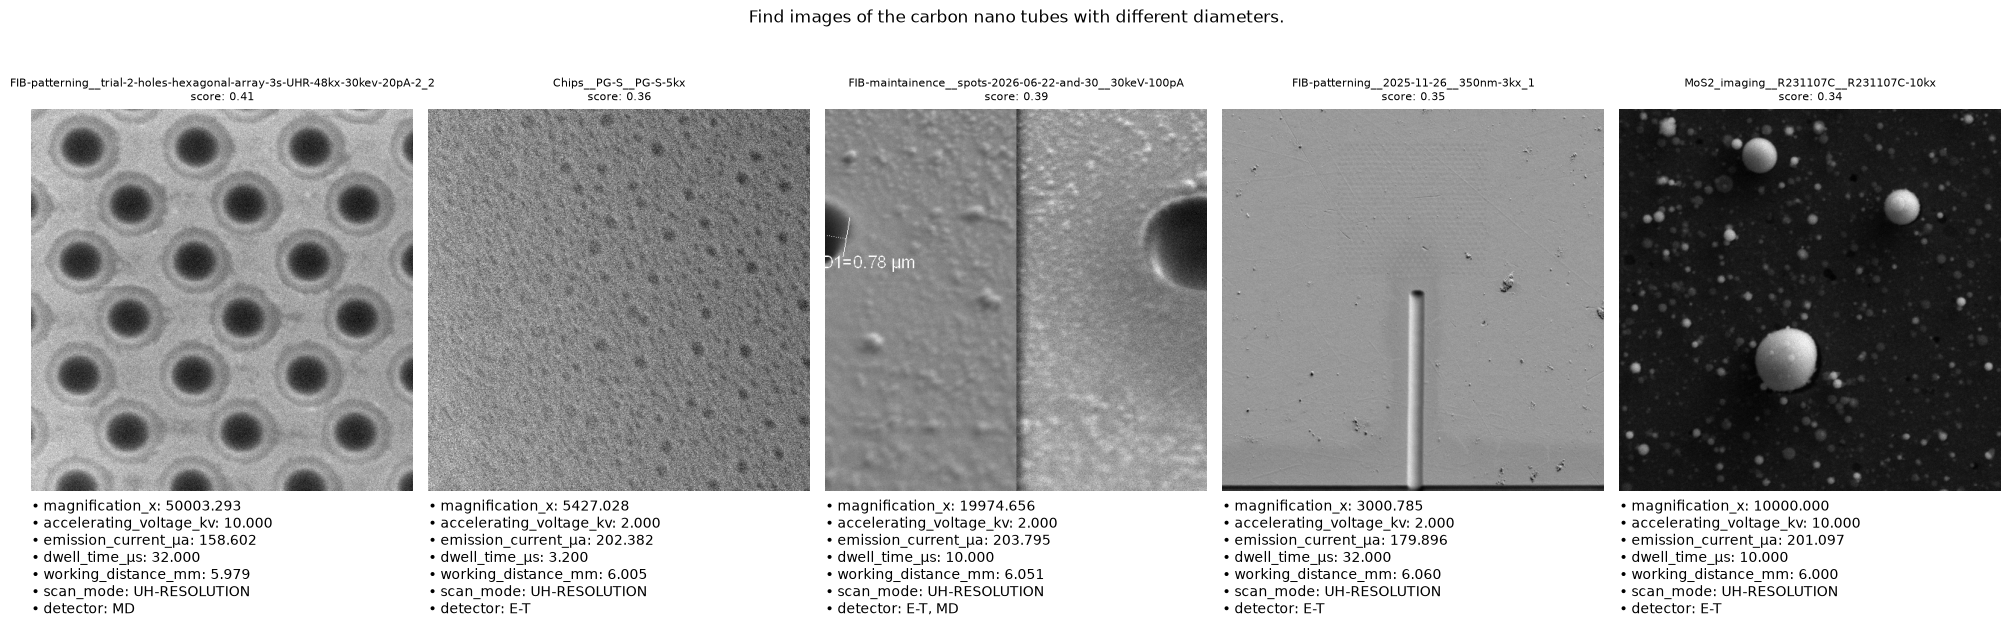

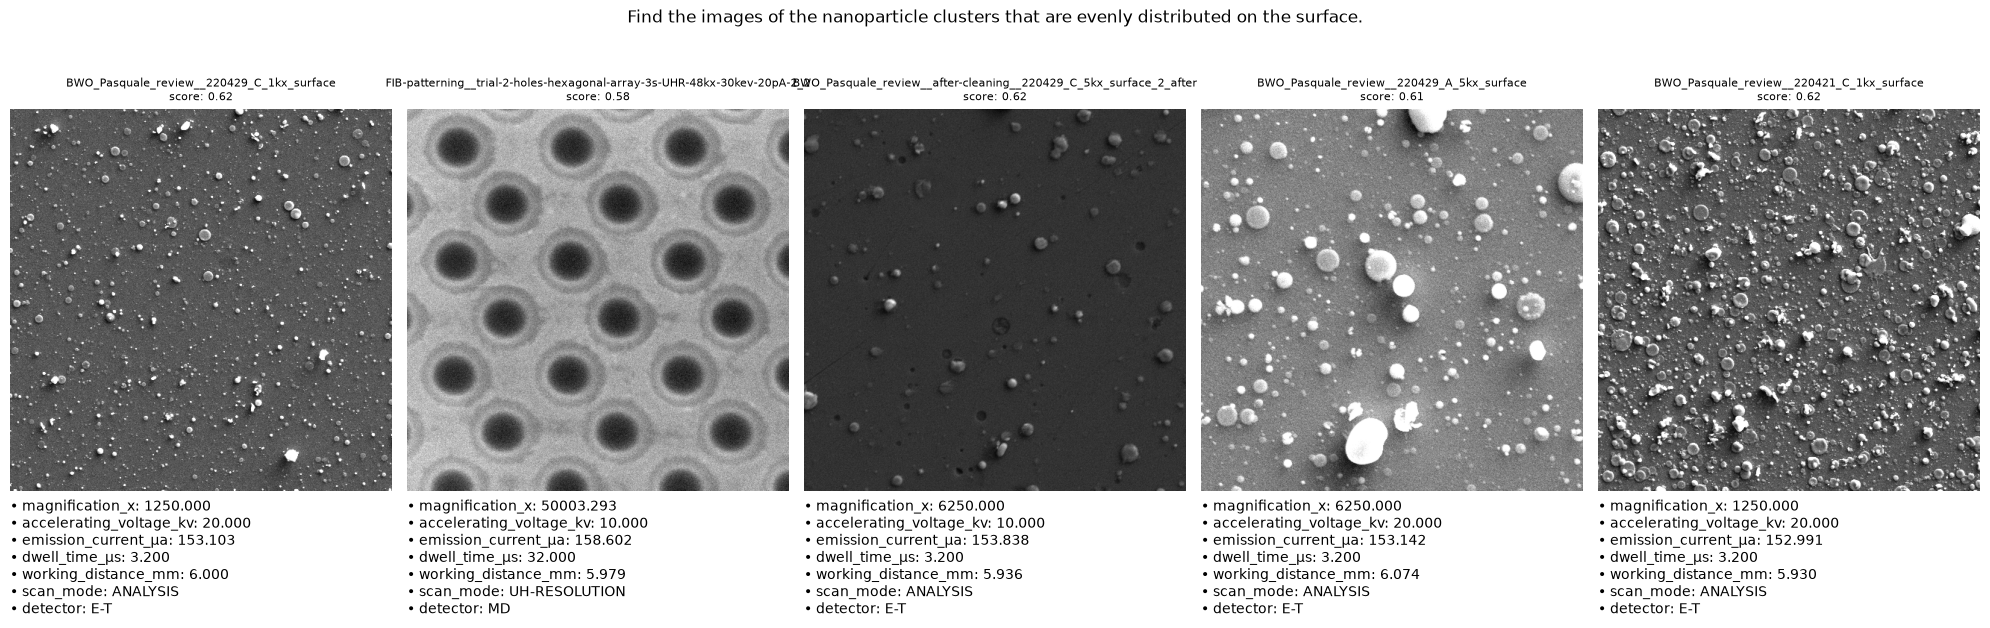

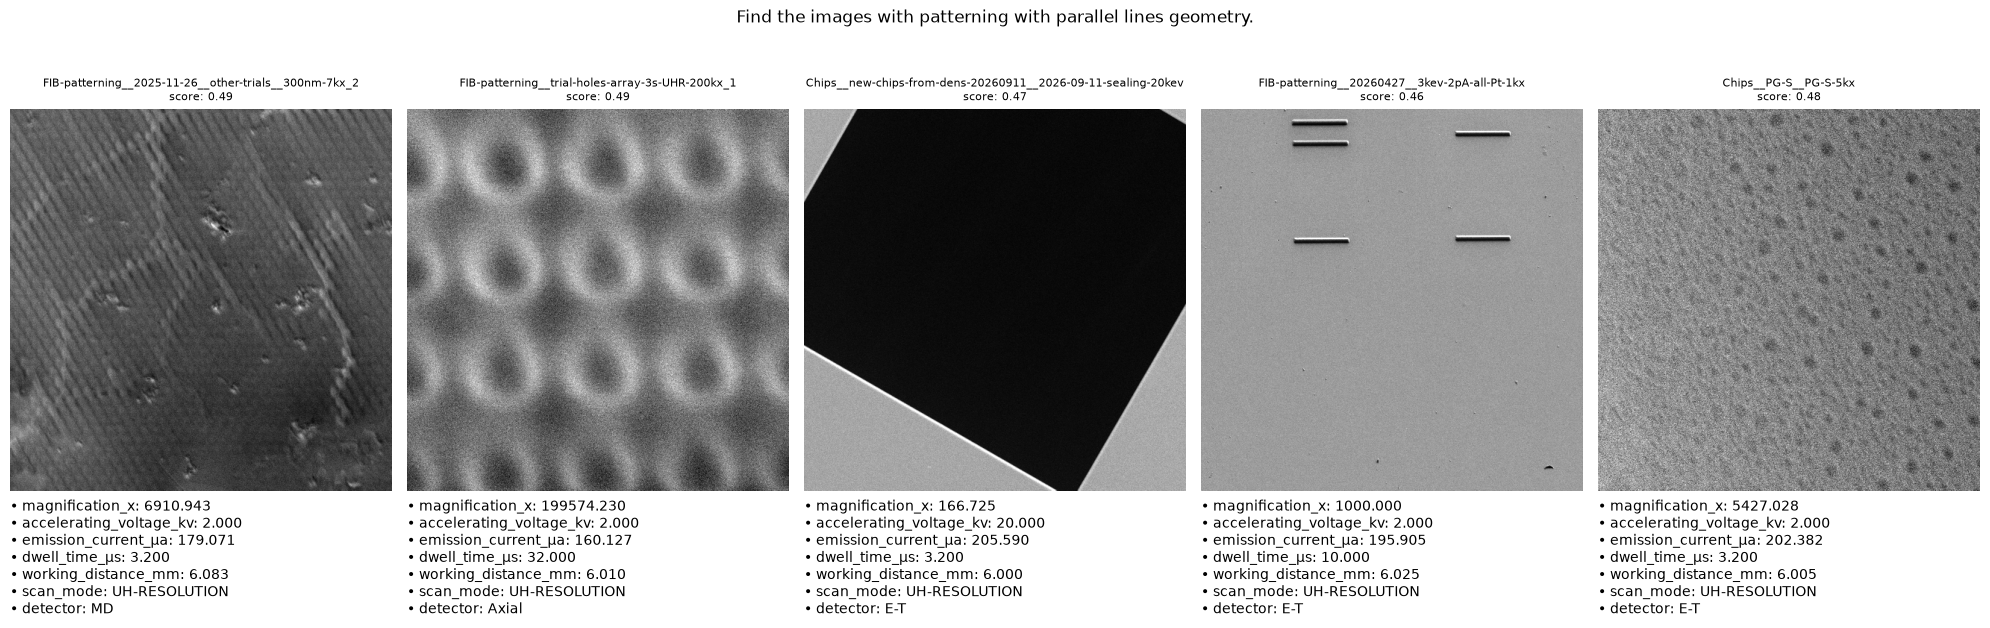

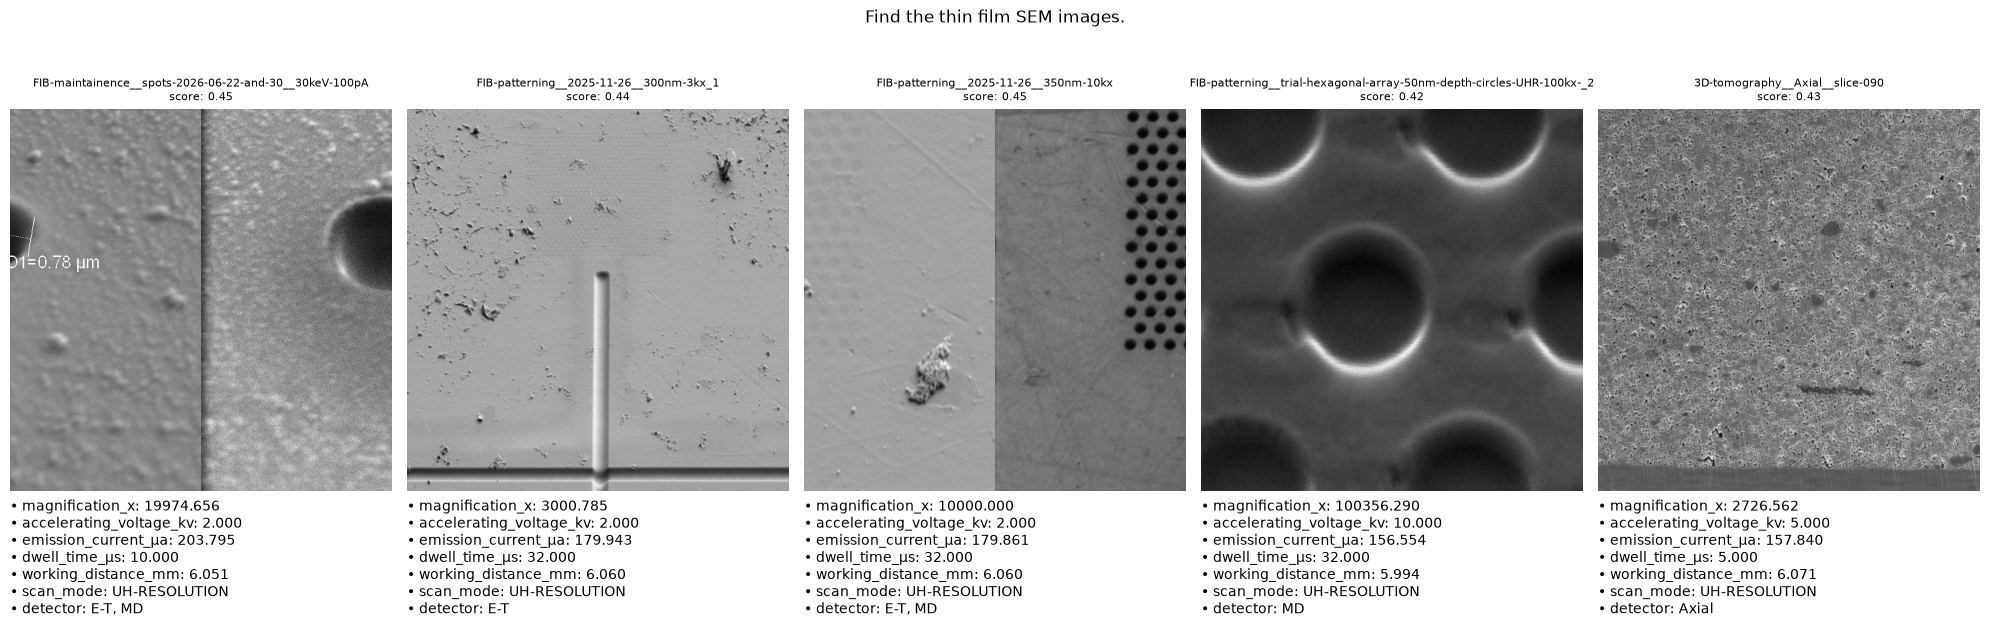

In [14]:
for query in TEXT_QUERIES:
    show_results(query, retriever.retrieve_documents(query, []))

### Metadata Queries

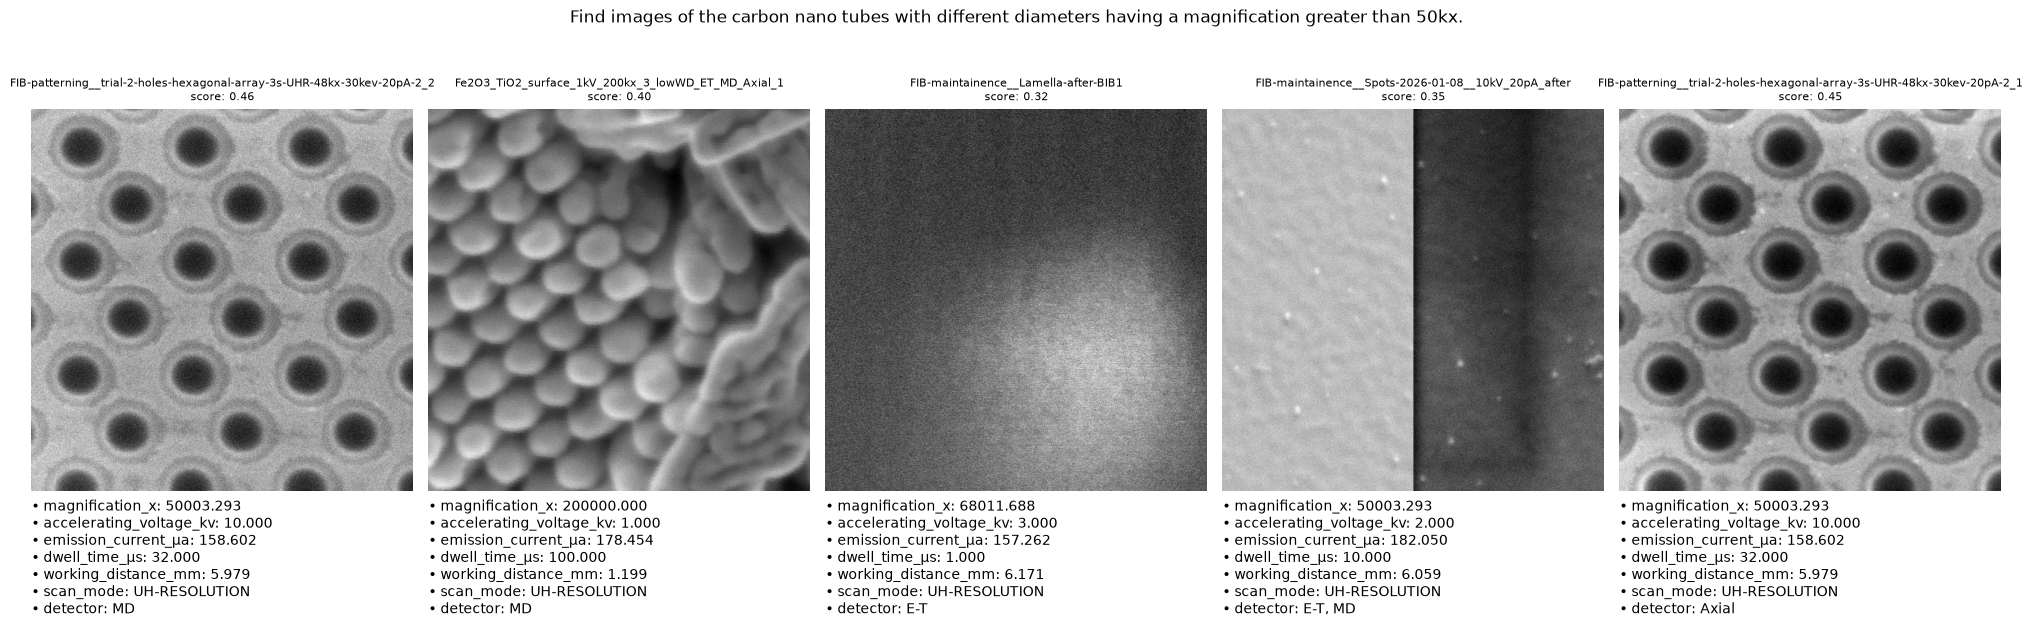

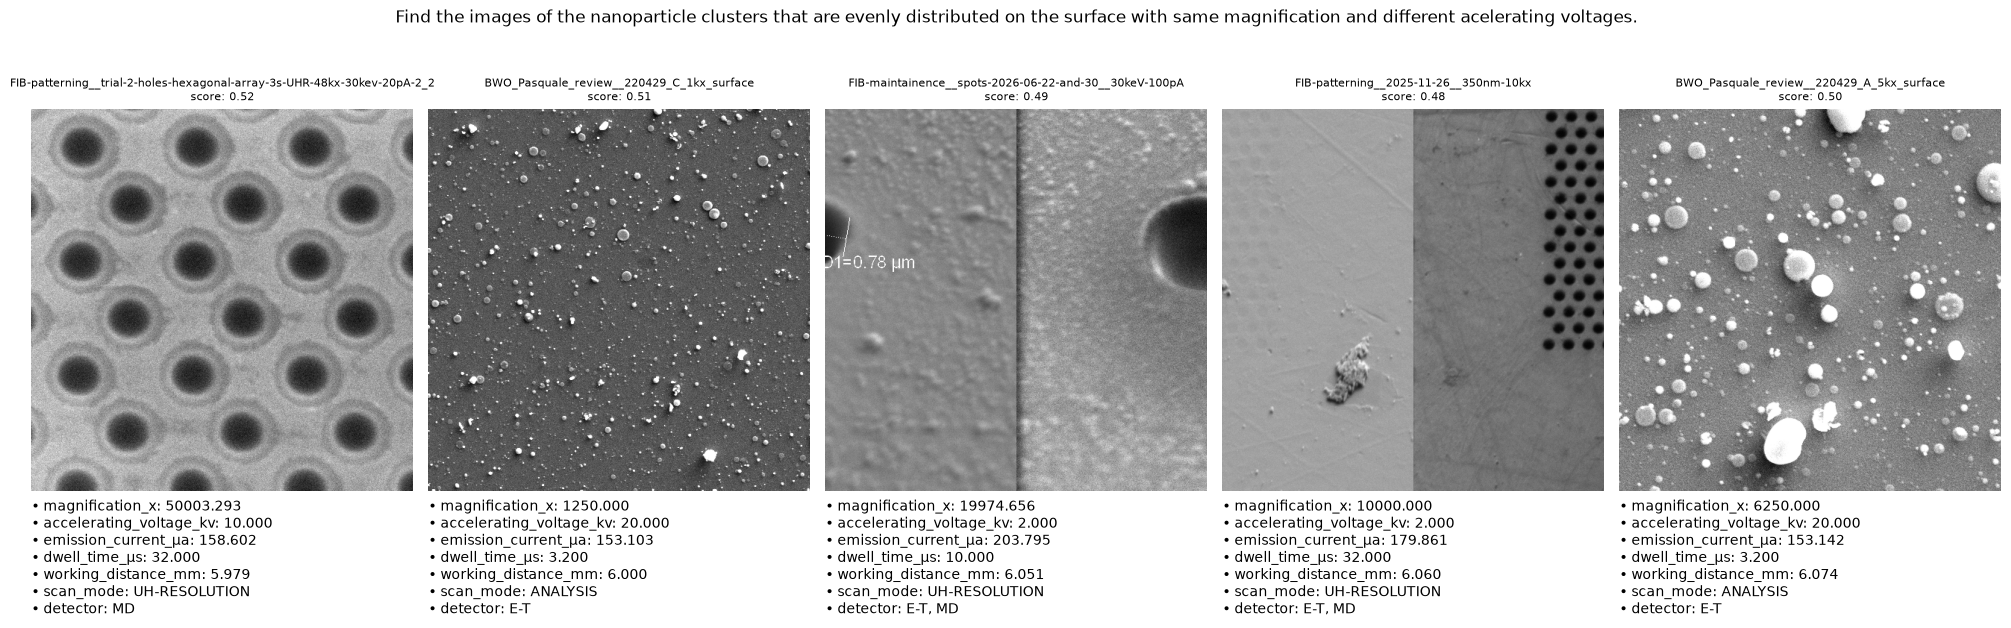

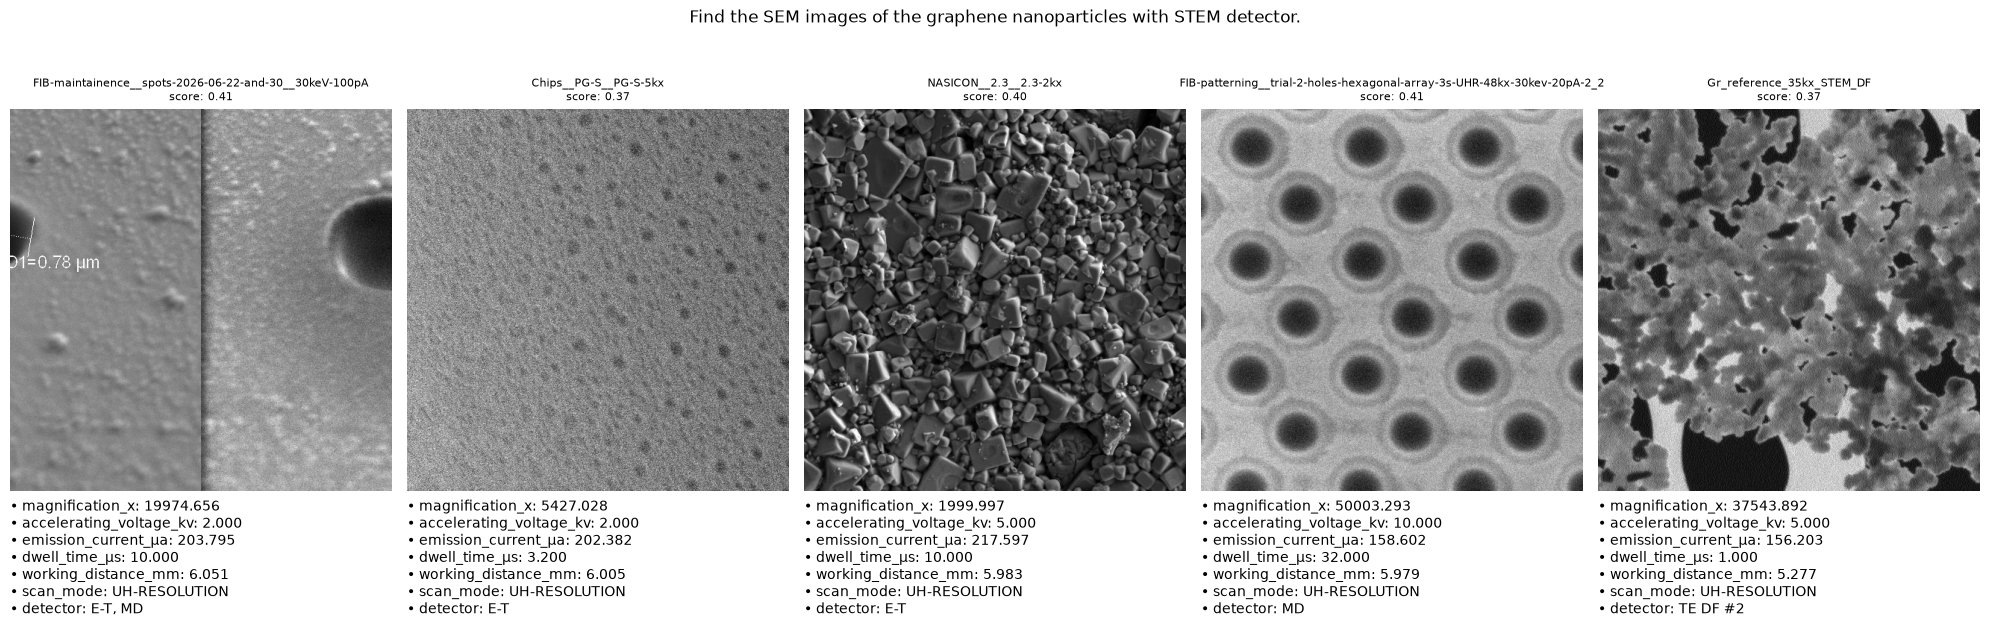

In [15]:
for query in TEXT_META_QUERIES:
    show_results(query, retriever.retrieve_documents(query, []))

## Image Retrieval

### No Metadata Queries

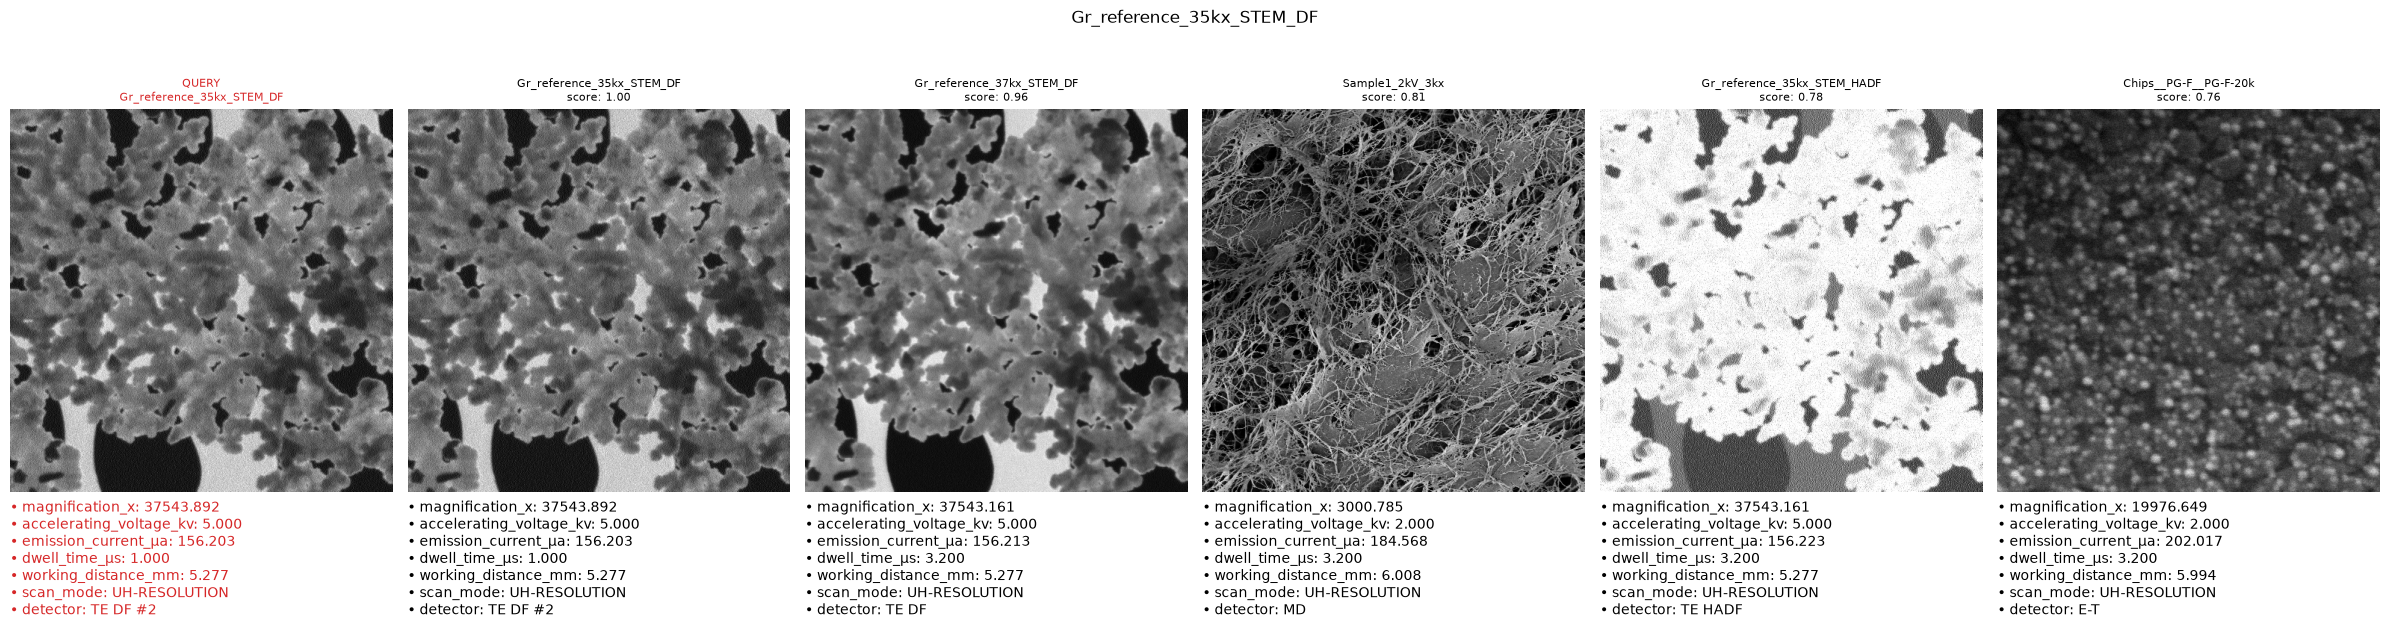

In [16]:
for image_id in IMAGE_QUERIES:
    data_url = encode_image(LAMEDataset.CROPS / f"{image_id}.npy")
    documents = retriever.retrieve_documents("", [data_url])
    show_results(image_id, documents, query_image_id=image_id)

### Metadata Queries

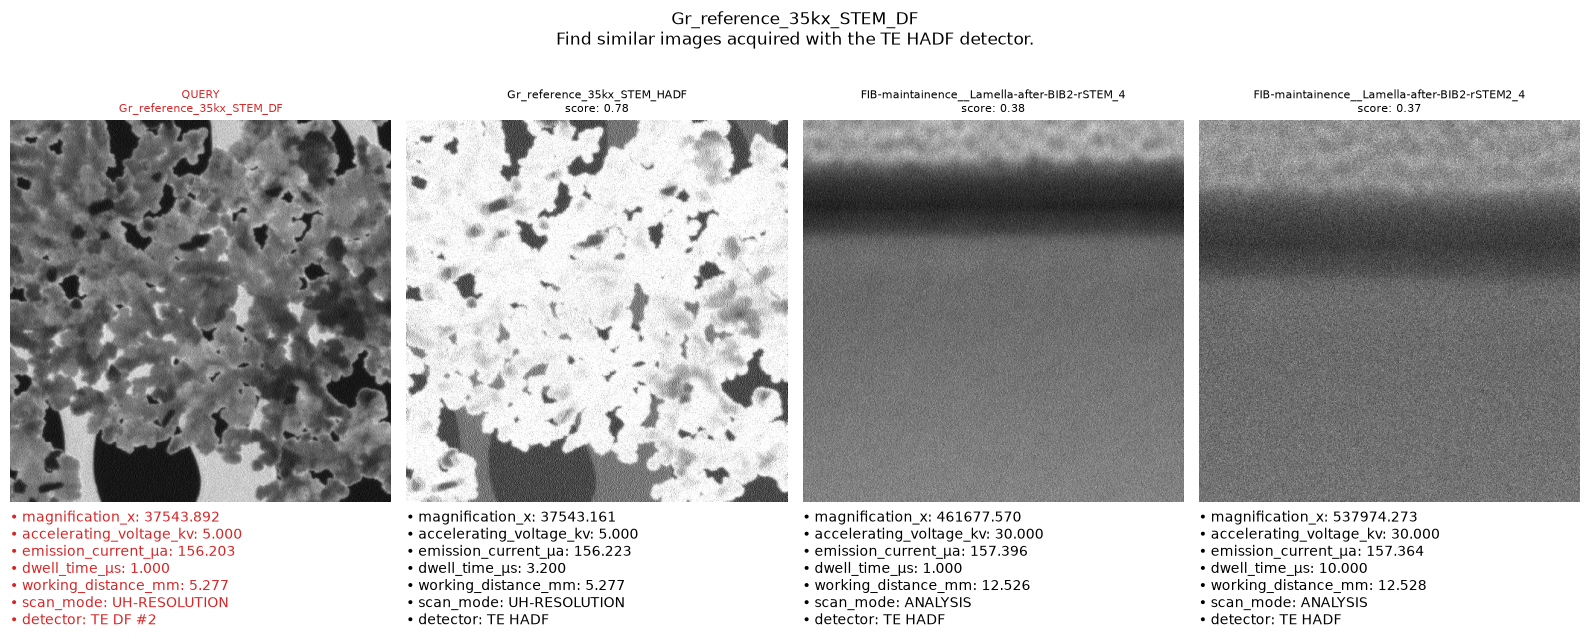

In [17]:
for image_id, text in IMAGE_META_QUERIES:
    data_url = encode_image(LAMEDataset.CROPS / f"{image_id}.npy")
    documents = retriever.retrieve_documents(text, [data_url])
    show_results(f"{image_id}\n{text}", documents, query_image_id=image_id)